# Лабораторная работа: вариант H1



## 8.1. Этап 1. Подготовка варианта и проверка сборки матрицы

Выбрать назначенный вариант из раздела 12 и реализовать функции:

$$
a(x,y),\quad c(x,y),\quad f(x,y),\quad g(x,y).
$$

По формуле (3) сформировать разреженную матрицу $A$ в формате **CSR** и правую часть $b$.

Плотная матрица размера

$$
(N_x-2)(N_y-2)\times(N_x-2)(N_y-2)
$$

не формируется.

### Проверка на сетке $N_x=N_y=8$

**1. Проверка структуры матрицы**

Вывести:
- Размер матрицы $A$.
- Число ненулевых элементов $\operatorname{nnz}(A)$.
- Портрет разреженной матрицы.
- Одну выбранную строку матрицы вместе с соответствующим линейным уравнением.

**2. Проверка симметричности и диагональных элементов**

Вычислить относительную меру нарушения симметрии:

$$
\boxed{
\varepsilon_{\mathrm{sym}}=
\frac{\|A-A^T\|_F}{\|A\|_F}
}
$$

Здесь $\|\cdot\|_F$ — норма Фробениуса:

$$
\|A\|_F=\sqrt{\sum_{i,j}A_{ij}^2}.
$$

Проверить положительность всех диагональных элементов:

$$
A_{ii}>0,\qquad i=0,\ldots,n-1.
$$

**3. Проверка положительности квадратичной формы**

Для нескольких заранее заданных ненулевых векторов $z$ проверить:

$$
\boxed{z^TAz>0,\qquad z\neq0.}
$$

Использовать три тестовых вектора:
- Постоянный.
- Знакопеременный.
- Синусоидальный.

**4. Проверка разложения Холецкого**

Для матрицы на сетке $N=8$ проверить возможность разложения Холецкого без диагонального сдвига:

$$
\boxed{A=LL^T,}
$$

где $L$ — нижняя треугольная матрица.

Преобразование $A$ в плотный формат разрешается **только для этой проверки на сетке $N=8$**.

### Критерии успешного выполнения этапа

Этап считается выполненным, если:

1. В каждой строке матрицы не более пяти ненулевых элементов:

   $$
   \operatorname{nnz}(A_{i,:})\leq5.
   $$

2. Мера нарушения симметрии не превышает уровень погрешности округления:

   $$
   \frac{\|A-A^T\|_F}{\|A\|_F}\approx0.
   $$

3. Численные проверки не противоречат формуле (4), устанавливающей положительную определённость матрицы:

   $$
   z^TAz>0,\qquad z\neq0.
   $$


In [661]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [701]:
class ProblemParams:
    @staticmethod
    def a(x, y):
        return 1.0 + 0.35 * np.sin(2.0 * np.pi * x) * np.sin(2.0 * np.pi * y)

    @staticmethod
    def c(x, y):
        return 0.0

    @staticmethod
    def f(x, y):
        return 30.0 * np.exp(-((x - 0.5) ** 2 + (y - 0.5) ** 2) / (2.0 * 0.12**2))

    @staticmethod
    def g(x, y):
        return 0.0

In [700]:
# R_new = 10.0 * (1.35 / 0.65)
# alpha = (R_new - 1.0) / (R_new + 1.0)  # 0.9081272084805654
# 
# ProblemParams.a = staticmethod(
#     lambda x, y: 1.0 + alpha * np.sin(2*np.pi*x) * np.sin(2*np.pi*y)
# )

In [664]:
# from math import erf, sqrt, pi
# 
# def gaussian_integral_1d(mu):
#     return 0.12 * sqrt(pi / 2) * (
#         erf((1 - mu) / (sqrt(2) * 0.12))
#         + erf(mu / (sqrt(2) * 0.12))
#     )
# 
# scale = (
#     gaussian_integral_1d(0.5)**2
#     / (gaussian_integral_1d(0.7) * gaussian_integral_1d(0.5))
# )
# 
# ProblemParams.f = staticmethod(
#     lambda x, y: scale * 30.0 * np.exp(
#         -((x - 0.7)**2 + (y - 0.5)**2) / (2 * 0.12**2)
#     )
# )

In [665]:
class SystemAssembler:
    def __init__(self, nx, ny):
        self.nx = nx
        self.ny = ny
        self.n = (nx - 2) * (ny - 2)

        self.hx = 1.0 / (nx - 1)
        self.hy = 1.0 / (ny - 1)

        self.x_grid = np.linspace(0.0, 1.0, nx)
        self.y_grid = np.linspace(0.0, 1.0, ny)
        self.a_grid = ProblemParams.a(self.x_grid[:, None], self.y_grid[None, :])

        self.rows = []
        self.cols = []
        self.data = []
        self.b = np.empty(self.n, dtype=np.float64)

    def _index(self, i, j):
        return (i - 1) + (j - 1) * (self.nx - 2)

    def _coupling_a_x(self, i, j):
        return (self.a_grid[i, j] + self.a_grid[i + 1, j]) / (2 * self.hx**2)

    def _coupling_a_y(self, i, j):
        return (self.a_grid[i, j] + self.a_grid[i, j + 1]) / (2 * self.hy**2)

    def _neighbours(self, i, j):
        return [
            (i - 1, j, self._coupling_a_x(i - 1, j)),
            (i + 1, j, self._coupling_a_x(i, j)),
            (i, j - 1, self._coupling_a_y(i, j - 1)),
            (i, j + 1, self._coupling_a_y(i, j)),
        ]

    def _construct_a(self, i, j):
        m = self._index(i, j)
        self.b[m] = ProblemParams.f(self.x_grid[i], self.y_grid[j])
        diagonal = ProblemParams.c(self.x_grid[i], self.y_grid[j])
        neighbours = self._neighbours(i, j)

        for ni, nj, weight in neighbours:
            diagonal += weight

            if 1 <= ni < self.nx - 1 and 1 <= nj < self.ny - 1:
                self.rows.append(m)
                self.cols.append(self._index(ni, nj))
                self.data.append(-weight)
            else:
                self.b[m] += weight * ProblemParams.g(self.x_grid[ni], self.y_grid[nj])

        self.rows.append(m)
        self.cols.append(m)
        self.data.append(diagonal)

    def assemble(self):
        for j in range(1, self.ny - 1):
            for i in range(1, self.nx - 1):
                self._construct_a(i, j)

        A = sp.coo_matrix(
            (self.data, (self.rows, self.cols)),
            shape=(self.n, self.n),
            dtype=np.float64,
        ).tocsr()

        return A, self.b


In [666]:
# class SystemAssembler:
#     def __init__(self, nx, ny, ordering="lex", seed=42):
#         if nx < 3 or ny < 3:
#             raise ValueError("Нужна хотя бы одна внутренняя точка по каждой оси")
# 
#         self.nx = nx
#         self.ny = ny
#         self.n = (nx - 2) * (ny - 2)
#         self.hx = 1.0 / (nx - 1)
#         self.hy = 1.0 / (ny - 1)
# 
#         self.x_grid = np.linspace(0.0, 1.0, nx)
#         self.y_grid = np.linspace(0.0, 1.0, ny)
#         self.a_grid = ProblemParams.a(self.x_grid[:, None], self.y_grid[None, :])
# 
#         width = nx - 2
#         if ordering == "lex":
#             self.old_to_new = np.arange(self.n, dtype=np.int64)
#         elif ordering == "snake":
#             self.old_to_new = np.empty(self.n, dtype=np.int64)
#             for jj in range(ny - 2):
#                 for ii in range(nx - 2):
#                     old = ii + jj * width
#                     new_ii = ii if jj % 2 == 0 else width - 1 - ii
#                     self.old_to_new[old] = new_ii + jj * width
#         elif ordering == "random":
#             self.old_to_new = np.random.default_rng(seed).permutation(self.n)
#         else:
#             raise ValueError("ordering должен быть lex, snake или random")
# 
#         self.rows = []
#         self.cols = []
#         self.data = []
#         self.b = np.empty(self.n, dtype=np.float64)
# 
#     def _index(self, i, j):
#         old = (i - 1) + (j - 1) * (self.nx - 2)
#         return int(self.old_to_new[old])
# 
#     def _coupling_a_x(self, i, j):
#         return (self.a_grid[i, j] + self.a_grid[i + 1, j]) / (2 * self.hx**2)
# 
#     def _coupling_a_y(self, i, j):
#         return (self.a_grid[i, j] + self.a_grid[i, j + 1]) / (2 * self.hy**2)
# 
#     def _neighbours(self, i, j):
#         return [
#             (i - 1, j, self._coupling_a_x(i - 1, j)),
#             (i + 1, j, self._coupling_a_x(i, j)),
#             (i, j - 1, self._coupling_a_y(i, j - 1)),
#             (i, j + 1, self._coupling_a_y(i, j)),
#         ]
# 
#     def _construct_a(self, i, j):
#         m = self._index(i, j)
#         self.b[m] = ProblemParams.f(self.x_grid[i], self.y_grid[j])
#         diagonal = ProblemParams.c(self.x_grid[i], self.y_grid[j])
# 
#         for ni, nj, weight in self._neighbours(i, j):
#             diagonal += weight
#             if 1 <= ni < self.nx - 1 and 1 <= nj < self.ny - 1:
#                 self.rows.append(m)
#                 self.cols.append(self._index(ni, nj))
#                 self.data.append(-weight)
#             else:
#                 self.b[m] += weight * ProblemParams.g(
#                     self.x_grid[ni], self.y_grid[nj]
#                 )
# 
#         self.rows.append(m)
#         self.cols.append(m)
#         self.data.append(diagonal)
# 
#     def assemble(self):
#         self.rows = []
#         self.cols = []
#         self.data = []
#         self.b = np.empty(self.n, dtype=np.float64)
# 
#         for j in range(1, self.ny - 1):
#             for i in range(1, self.nx - 1):
#                 self._construct_a(i, j)
# 
#         A = sp.coo_matrix(
#             (self.data, (self.rows, self.cols)),
#             shape=(self.n, self.n),
#             dtype=np.float64,
#         ).tocsr()
#         return A, self.b

In [667]:
# class OperatorAssembler:
#     def __init__(self, nx, ny):
#         if nx < 3 or ny < 3:
#             raise ValueError("Нужна хотя бы одна внутренняя точка по каждой оси")
# 
#         self.nx = nx
#         self.ny = ny
#         self.n = (nx - 2) * (ny - 2)
# 
#         self.hx = 1.0 / (nx - 1)
#         self.hy = 1.0 / (ny - 1)
# 
#         self.x_grid = np.linspace(0.0, 1.0, nx)
#         self.y_grid = np.linspace(0.0, 1.0, ny)
# 
#     def assemble(self):
#         nx, ny = self.nx, self.ny
# 
#         X, Y = np.meshgrid(self.x_grid, self.y_grid, indexing="xy")
# 
#         a = np.broadcast_to(ProblemParams.a(X, Y), (ny, nx))
#         ci = ProblemParams.c(X[1:-1, 1:-1], Y[1:-1, 1:-1])
# 
#         hx2 = self.hx**2
#         hy2 = self.hy**2
#         ai = a[1:-1, 1:-1]
# 
#         wl = (ai + a[1:-1, :-2]) / (2 * hx2)
#         wr = (ai + a[1:-1, 2:]) / (2 * hx2)
#         wd = (ai + a[:-2, 1:-1]) / (2 * hy2)
#         wu = (ai + a[2:, 1:-1]) / (2 * hy2)
# 
#         diagonal = (wl + wr + wd + wu + ci).ravel().copy()
# 
#         def matvec(v):
#             u = np.zeros((ny, nx), dtype=np.float64)
#             u[1:-1, 1:-1] = np.asarray(v).reshape(ny - 2, nx - 2)
# 
#             ui = u[1:-1, 1:-1]
# 
#             out = (
#                 wl * (ui - u[1:-1, :-2])
#                 + wr * (ui - u[1:-1, 2:])
#                 + wd * (ui - u[:-2, 1:-1])
#                 + wu * (ui - u[2:, 1:-1])
#                 + ci * ui
#             )
# 
#             return out.ravel()
# 
#         A = sp.linalg.LinearOperator(
#             (self.n, self.n),
#             matvec=matvec,
#             dtype=np.float64,
#         )
# 
#         b = np.broadcast_to(
#             ProblemParams.f(X[1:-1, 1:-1], Y[1:-1, 1:-1]),
#             (ny - 2, nx - 2),
#         ).ravel().copy()
# 
#         return A, b, diagonal

In [668]:
def with_separator(func):
    def wrapper(*args, **kwargs):
        separator = "‒" * 100
        print(f"\n{separator}")

        result = func(*args, **kwargs)

        print(f"{separator}\n")
        return result

    return wrapper



‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒
1. Размер матрицы, число ненулевых элементов, портрет и одна строка с уравнением
Размер сетки: 8 x 8
Размер матрицы: (36, 36); число ненулевых элементов: 156
Максимальное число ненулевых элементов в строке: 5
Уравнение для узла (3, 3):
-54.2416·u[3,2] -54.2416·u[2,3] +206.4831·u[3,3] -49.0000·u[4,3] -49.0000·u[3,4] = 21.0498


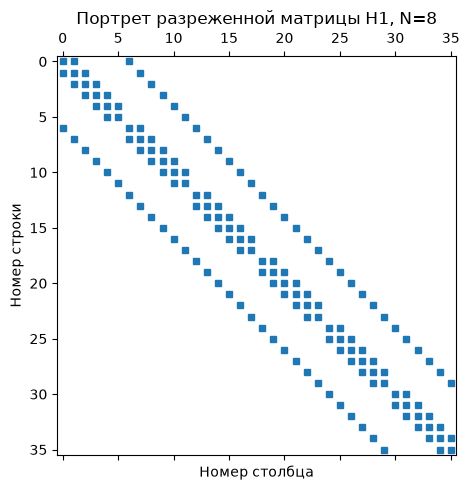

‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒


‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒
2. Относительная мера симметрии и положительность диагональных элементов
Относительная мера нарушения симметрии: 0.000e+00
Минимальный диагональный элемент: 143.071609
‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒


‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒
3. Проверка v.T @ A @ v > 0 для нескольких ненулевых векторов
v.T @ A @ v (Постоянный): 1176.000000000000
v.T @ A @ v (Знакопеременный): 12936.000000000002
v.T @ A @ v (Синусоидальный): 237.773748166292
‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒


‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒
4. Проверка возмо

In [669]:
nx = ny = 8
A, b = SystemAssembler(nx, ny).assemble()


@with_separator
def check_1():
    print(
        "1. Размер матрицы, число ненулевых элементов, портрет и одна строка с уравнением"
    )

    print(f"Размер сетки: {nx} x {ny}")
    print(f"Размер матрицы: {A.shape}; число ненулевых элементов: {A.nnz}")
    print(f"Максимальное число ненулевых элементов в строке: {np.diff(A.indptr).max()}")

    i = j = 3
    m = (i - 1) + (j - 1) * (nx - 2)

    row_start, row_end = A.indptr[m], A.indptr[m + 1]

    terms = []

    for k in range(row_start, row_end):
        col = A.indices[k]
        ni = col % (nx - 2) + 1
        nj = col // (nx - 2) + 1

        coefficient = A.data[k]
        terms.append(f"{coefficient:+.4f}·u[{ni},{nj}]")

    equation = " ".join(terms).lstrip("+")
    print(f"Уравнение для узла ({i}, {j}):")
    print(f"{equation} = {b[m]:.4f}")

    plt.figure(figsize=(5, 5))
    plt.spy(A, markersize=4)
    plt.title(f"Портрет разреженной матрицы H1, N={nx}")
    plt.xlabel("Номер столбца")
    plt.ylabel("Номер строки")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "matrix_portrait.png", dpi=200, bbox_inches="tight")
    plt.show()


@with_separator
def check_2():
    print("2. Относительная мера симметрии и положительность диагональных элементов")

    symmetry_error = sp.linalg.norm(A - A.T, ord="fro") / sp.linalg.norm(A, ord="fro")
    diagonal = A.diagonal()

    print(f"Относительная мера нарушения симметрии: {symmetry_error:.3e}")
    print(f"Минимальный диагональный элемент: {diagonal.min():.6f}")

    assert symmetry_error < 1e-14
    assert np.all(diagonal > 0)


@with_separator
def check_3():
    print("3. Проверка v.T @ A @ v > 0 для нескольких ненулевых векторов")

    grid_i = np.tile(np.arange(1, nx - 1), ny - 2)
    grid_j = np.repeat(np.arange(1, ny - 1), nx - 2)

    tests = {
        "Постоянный": np.ones(A.shape[0]),
        "Знакопеременный": (-1.0) ** (grid_i + grid_j),
        "Синусоидальный": (
            np.sin(np.pi * grid_i / (nx - 1)) * np.sin(np.pi * grid_j / (ny - 1))
        ),
    }

    for name, v in tests.items():
        value = v @ (A @ v)
        print(f"v.T @ A @ v ({name}): {value:.12f}")
        assert value > 0


@with_separator
def check_4():
    print("4. Проверка возможности разложения Холецкого без диагонального сдвига")

    dense_A = A.toarray()
    L = np.linalg.cholesky(dense_A)

    assert np.allclose(L @ L.T, dense_A)
    print("Разложение Холецкого успешно выполнено без диагонального сдвига")


check_1()
check_2()
check_3()
check_4()



## 8.2. Этап 2. Реализация и проверка стационарных методов

Реализовать **методы Якоби, Зейделя и ПВР**.

Во всех методах использовать:
- Начальное приближение $x^{(0)} = 0$.
- Критерий остановки:

  $$
  \eta_s = \frac{\|b - Ax^{(s)}\|_2}{\|b\|_2} \leq \varepsilon_{\mathrm{res}},
  \qquad \varepsilon_{\mathrm{res}} = 10^{-8}.
  $$

- Явное ограничение максимального числа итераций.

На каждой итерации сохранять истинную нормированную невязку.

### Проверка на тестовой системе

Для сетки $N = 32$ задать вектор известного решения:

$$
u_m^* = 1 + \sin\left(\frac{2\pi m}{n}\right)
+ 0.1\cos\left(\frac{6\pi m}{n}\right),
\qquad m = 0,\ldots,n-1.
$$

Сформировать правую часть:

$$
b^* = Au^*
$$

и решить систему:

$$
Ax = b^*.
$$

Для каждого метода вычислить:

**Нормированную невязку:**

$$
\eta_s = \frac{\|b^* - Ax^{(s)}\|_2}{\|b^*\|_2}.
$$

**Относительную погрешность решения:**

$$
\delta_s = \frac{\|u^* - x^{(s)}\|_2}{\|u^*\|_2}.
$$

Проверить достижение заданного порога невязки и сопоставить $\eta_s$ с $\delta_s$.

Если метод достиг максимального числа итераций, запуск фиксируется как **не сошедшийся** при заданных параметрах.

### Расчёты для варианта H1

После проверки решить систему назначенного варианта на сетках:

$$
N = 32,\quad N = 64.
$$

Для метода ПВР:

1. Исследовать не менее 10 значений параметра $\omega$ из интервала $[1, 1.95]$ на сетке $N=64$.
2. Уточнить поиск в окрестности лучшего найденного значения $\omega$.

Полученный параметр следует называть **наилучшим среди проверенных**, а не теоретически оптимальным.


In [670]:
EPS_RES = 10 ** (-8)
MAX_ITERS = 100000


def stopping_criterion(A, b, x_s):
    return (np.linalg.norm(b - A @ x_s, ord=2) / np.linalg.norm(b, ord=2)) < EPS_RES


def initial_guess(b: np.ndarray) -> np.ndarray:
    return np.zeros_like(b, dtype=np.float64)


In [671]:
# def initial_guess(b: np.ndarray) -> np.ndarray:
#     N = int(np.sqrt(b.size)) + 2
#     x = np.linspace(0.0, 1.0, N)[1:-1]
#     X, Y = np.meshgrid(x, x, indexing="xy")
# 
#     return (0.3 * np.sin(np.pi * X) * np.sin(np.pi * Y)).ravel()
# 
# def initial_guess(nx: int, ny: int) -> np.ndarray:
#     x = np.linspace(0.0, 1.0, nx)[1:-1]
#     y = np.linspace(0.0, 1.0, ny)[1:-1]
# 
#     X, Y = np.meshgrid(x, y, indexing="xy")
# 
#     return (0.3 * np.sin(np.pi * X) * np.sin(np.pi * Y)).ravel()

`SolveResult` хранит решение, число итераций, историю истинной относительной невязки и признак сходимости. Погрешность относительно известного решения вычисляется в `Tester`.

Для CG/PCG поле `matvec_count` учитывает все умножения на исходную матрицу `A` внутри решателя, включая вычисление начальной и проверочных невязок. При текущей проверке после каждого шага оно равно `1 + 2 * iterations`. Действия предобуславливателя и проверки вне решателя в этот счётчик не входят. Для остальных методов значение — `None`.


In [672]:
from dataclasses import dataclass


@dataclass
class SolveResult:
    x: np.ndarray
    iterations: int
    residuals: list[float]
    converged: bool
    # Число умножений на A; для методов без счётчика — None.
    matvec_count: int | None = None



## Метод Якоби

Рассмотрим систему линейных алгебраических уравнений:

$$
Ax=b.
$$

Представим матрицу $A$ в виде суммы:

$$
A=L+D+U,
$$

где:
- $D=\operatorname{diag}(a_{11},\ldots,a_{nn})$ — диагональная матрица;
- $L$ — строго нижняя треугольная часть матрицы $A$;
- $U$ — строго верхняя треугольная часть матрицы $A$.

### 1. Вывод итерационной формулы

Перепишем исходную систему:

$$
(L+D+U)x=b.
$$

Выразим диагональную часть:

$$
Dx=b-(L+U)x.
$$

В методе Якоби значения правой части берутся с предыдущей итерации:

$$
Dx^{(s+1)}=b-(L+U)x^{(s)}.
$$

Предполагая, что все диагональные элементы ненулевые, получаем:

$$
\boxed{x^{(s+1)}=D^{-1}\left(b-(L+U)x^{(s)}\right).}
$$

В покомпонентной форме:

$$
\boxed{
x_i^{(s+1)}=
\frac{1}{a_{ii}}
\left(
b_i-\sum_{j\ne i}a_{ij}x_j^{(s)}
\right),\qquad i=1,\ldots,n.
}
$$

**Особенность метода Якоби:** все компоненты нового приближения $x^{(s+1)}$ вычисляются исключительно через компоненты предыдущего приближения $x^{(s)}$. Поэтому порядок вычисления компонент произвольный.

### 2. Форма через невязку

Введём вектор невязки:

$$
r^{(s)}=b-Ax^{(s)}.
$$

Учитывая $A=L+D+U$, перепишем итерационную формулу:

$$
x^{(s+1)}
=D^{-1}\left(b-(A-D)x^{(s)}\right).
$$

Отсюда:

$$
\boxed{
x^{(s+1)}=x^{(s)}+D^{-1}r^{(s)}.
}
$$

Именно эта формула используется в программной реализации:

```python
r = b - A @ x
x += r / diagonal
```

Здесь деление выполняется покомпонентно, поэтому явно формировать $D^{-1}$ не требуется.

### 3. Условия сходимости

Метод Якоби представляет собой стационарный итерационный процесс:

$$
x^{(s+1)}=R_Jx^{(s)}+D^{-1}b,
$$

где матрица перехода:

$$
\boxed{R_J=-D^{-1}(L+U)=I-D^{-1}A.}
$$

**Необходимое и достаточное условие сходимости** при любом начальном приближении:

$$
\boxed{\rho(R_J)<1,}
$$

где $\rho(R_J)=\max_i|\lambda_i(R_J)|$ — спектральный радиус матрицы перехода.

Достаточным условием сходимости является **строгое диагональное преобладание** матрицы $A$:

$$
\boxed{
|a_{ii}|>\sum_{j\ne i}|a_{ij}|,
\qquad \forall i.
}
$$

Действительно, для матричной нормы, подчинённой векторной максимум-норме:

$$
\rho(R_J)\leq\|R_J\|_\infty
=\max_i\sum_{j\ne i}\left|\frac{a_{ij}}{a_{ii}}\right|<1.
$$

Строгое диагональное преобладание — **достаточное, но не необходимое условие**: метод может сходиться и при его отсутствии.

### 4. Скорость сходимости

Обозначим точное решение через $x^*$, а погрешность итерации через

$$
e^{(s)}=x^*-x^{(s)}.
$$

Тогда:

$$
e^{(s+1)}=R_Je^{(s)},
$$

следовательно,

$$
\boxed{e^{(s)}=R_J^se^{(0)}.}
$$

Асимптотическая скорость сходимости определяется спектральным радиусом $\rho(R_J)$.

Чем ближе $\rho(R_J)$ к нулю, тем быстрее обычно уменьшается погрешность. При $\rho(R_J)$, близком к единице, сходимость медленная.


In [673]:
class Jacobi:
    @staticmethod
    def solve(A, b, x0, eps_res=EPS_RES, maxiter=MAX_ITERS) -> SolveResult:
        b = np.asarray(b, dtype=np.float64)
        x = np.array(x0, dtype=np.float64, copy=True)

        diagonal = A.diagonal()
        if np.any(diagonal == 0):
            raise ValueError("На диагонали матрицы есть нулевые элементы")

        b_norm = np.linalg.norm(b)
        if b_norm == 0:
            raise ValueError("Норма правой части равна нулю")

        residuals = []
        iterations = 0

        while True:
            r = b - A @ x
            residuals.append(np.linalg.norm(r) / b_norm)

            if residuals[-1] <= eps_res or iterations >= maxiter:
                break

            x += r / diagonal
            iterations += 1

        return SolveResult(
            x=x,
            iterations=iterations,
            residuals=residuals,
            converged=residuals[-1] <= eps_res,
        )



## Метод Зейделя

Рассмотрим СЛАУ:

$$
Ax=b.
$$

Представим матрицу в виде:

$$
A=L+D+U,
$$

где:
- $D$ — диагональная часть матрицы;
- $L$ — строго нижняя треугольная часть;
- $U$ — строго верхняя треугольная часть.

### 1. Вывод итерационной формулы

Перепишем исходную систему:

$$
(L+D+U)x=b.
$$

В отличие от метода Якоби, метод Зейделя использует уже вычисленные компоненты нового приближения:

$$
(D+L)x^{(s+1)}=b-Ux^{(s)}.
$$

Отсюда:

$$
\boxed{
x^{(s+1)}=(D+L)^{-1}(b-Ux^{(s)}).
}
$$

В покомпонентной форме:

$$
\boxed{
x_i^{(s+1)}=
\frac{1}{a_{ii}}
\left(
b_i
-\sum_{j<i}a_{ij}x_j^{(s+1)}
-\sum_{j>i}a_{ij}x_j^{(s)}
\right).
}
$$

**Главное отличие от метода Якоби:** при вычислении $x_i^{(s+1)}$ используются уже обновлённые значения $x_j^{(s+1)}$ для $j<i$.

Поэтому компоненты вычисляются последовательно, в порядке возрастания индекса $i$.

### 2. Форма через покомпонентную невязку

Рассмотрим $i$-ю компоненту невязки:

$$
r_i=b_i-\sum_{j=1}^{n}a_{ij}x_j.
$$

Если компоненты $x_1,\ldots,x_{i-1}$ уже обновлены, то очередной шаг Зейделя можно записать:

$$
\boxed{
x_i\leftarrow x_i+\frac{r_i}{a_{ii}}.
}
$$

После обновления $x_i$ следующий компонентный шаг использует его новое значение.

Это позволяет реализовать метод **in-place**, без хранения дополнительного вектора предыдущего приближения.

### 3. Условия сходимости

Матрица перехода метода Зейделя:

$$
\boxed{
R_S=-(D+L)^{-1}U.
}
$$

Необходимое и достаточное условие сходимости при произвольном начальном приближении:

$$
\boxed{\rho(R_S)<1.}
$$

Достаточные условия сходимости:

1. Строгое диагональное преобладание матрицы $A$.
2. Симметричность и положительная определённость матрицы $A$.

Для варианта H1 матрица $A$ симметрична и положительно определена, поэтому метод Зейделя сходится при любом начальном приближении.

### 4. Скорость сходимости

Обозначим погрешность:

$$
e^{(s)}=x^*-x^{(s)}.
$$

Тогда:

$$
e^{(s+1)}=R_Se^{(s)},
$$

откуда:

$$
\boxed{
e^{(s)}=R_S^se^{(0)}.
}
$$

In [674]:
class Seidel:
    @staticmethod
    def solve(A, b, x0, eps_res=EPS_RES, maxiter=MAX_ITERS) -> SolveResult:
        return SuccessiveRelaxation.solve(
            A, b, omega=1, x0=x0, eps_res=eps_res, maxiter=maxiter
        )



## Метод последовательной верхней релаксации (ПВР, SOR)

Метод последовательной релаксации обобщает метод Зейделя путём введения **параметра релаксации** $\omega$.

Рассматривается система:

$$
Ax=b,\qquad A=L+D+U.
$$

### 1. Вывод итерационной формулы

Умножим исходную систему на $\omega$:

$$
\omega Ax=\omega b.
$$

Выберем матрицу расщепления:

$$
M_\omega=D+\omega L.
$$

Тогда:

$$
N_\omega=M_\omega-\omega A
=(1-\omega)D-\omega U.
$$

Получаем итерационный процесс:

$$
\boxed{
(D+\omega L)x^{(s+1)}
=
\omega b+\big((1-\omega)D-\omega U\big)x^{(s)}.
}
$$

В покомпонентной форме:

$$
\boxed{
x_i^{(s+1)}
=
(1-\omega)x_i^{(s)}
+
\frac{\omega}{a_{ii}}
\left(
b_i
-\sum_{j<i}a_{ij}x_j^{(s+1)}
-\sum_{j>i}a_{ij}x_j^{(s)}
\right).
}
$$

### 2. Связь с методом Зейделя

Обозначим через $\widetilde{x}_i^{(s+1)}$ значение, которое получилось бы на очередном шаге Зейделя.

Тогда:

$$
\boxed{
x_i^{(s+1)}
=
(1-\omega)x_i^{(s)}
+
\omega\widetilde{x}_i^{(s+1)}.
}
$$

Или через покомпонентную невязку:

$$
\boxed{
x_i\leftarrow x_i+\omega\frac{r_i}{a_{ii}}.
}
$$

Здесь $r_i$ вычисляется с учётом уже обновлённых предыдущих компонент.

При разных значениях $\omega$:

- $0<\omega<1$ — последовательная нижняя релаксация;
- $\omega=1$ — метод Зейделя;
- $1<\omega<2$ — последовательная верхняя релаксация.

При $\omega>1$ поправка метода Зейделя увеличивается, что может ускорить сходимость.

### 3. Условия сходимости

Матрица перехода:

$$
\boxed{
R_\omega=
(D+\omega L)^{-1}
\big((1-\omega)D-\omega U\big).
}
$$

Необходимое и достаточное условие сходимости при любом начальном приближении:

$$
\boxed{\rho(R_\omega)<1.}
$$

**Теорема:** если матрица $A$ симметрична и положительно определена, то метод последовательной релаксации сходится при

$$
\boxed{0<\omega<2}
$$

для любого начального приближения.

Поскольку матрица варианта H1 является SPD, это условие обеспечивает сходимость метода.

In [675]:
class SOR:
    @staticmethod
    def solve(A, b, x0, omega, eps_res=EPS_RES, maxiter=MAX_ITERS) -> SolveResult:
        if not 1 <= omega < 2:
            raise ValueError("Параметр ω должен принадлежать полуинтервалу [1, 2)")

        return SuccessiveRelaxation.solve(
            A, b, omega=omega, x0=x0, eps_res=eps_res, maxiter=maxiter
        )


In [676]:
from numba import njit


class SuccessiveRelaxation:
    @staticmethod
    @njit
    def _sr_iteration(indptr, indices, data, diagonal, b, x, omega):
        for i in range(len(b)):
            row_sum = 0.0

            for k in range(indptr[i], indptr[i + 1]):
                j = indices[k]
                row_sum += data[k] * x[j]

            x[i] += omega * (b[i] - row_sum) / diagonal[i]

    @staticmethod
    def solve(A, b, x0, omega, eps_res=EPS_RES, maxiter=MAX_ITERS) -> SolveResult:
        if not 0 < omega < 2:
            raise ValueError("Параметр ω должен принадлежать интервалу (0, 2)")

        if not sp.isspmatrix_csr(A):
            raise TypeError("Матрица должна быть в формате CSR")

        b = np.asarray(b, dtype=np.float64)
        x = np.array(x0, dtype=np.float64, copy=True)

        diagonal = A.diagonal()
        if np.any(diagonal == 0):
            raise ValueError("На диагонали матрицы есть нулевые элементы")

        b_norm = np.linalg.norm(b)
        if b_norm == 0:
            raise ValueError("Норма правой части равна нулю")

        residuals = []
        iterations = 0

        while True:
            r = b - A @ x
            residuals.append(np.linalg.norm(r) / b_norm)

            if residuals[-1] <= eps_res or iterations >= maxiter:
                break

            SuccessiveRelaxation._sr_iteration(
                A.indptr, A.indices, A.data, diagonal, b, x, omega
            )
            iterations += 1

        return SolveResult(
            x=x,
            iterations=iterations,
            residuals=residuals,
            converged=residuals[-1] <= eps_res,
        )


In [677]:
class Tester:
    def __init__(self, methods, eps_res=EPS_RES, maxiter=MAX_ITERS):
        self.methods = methods
        self.eps_res = eps_res
        self.maxiter = maxiter

    @with_separator
    def test_known_solution(self, solution, nx, ny):
        A, _ = SystemAssembler(nx, ny).assemble()
        n = A.shape[0]

        u_exact = np.asarray(solution, dtype=np.float64)

        if u_exact.shape != (n,):
            raise ValueError(f"Ожидается вектор решения размера {(n,)}")

        b_star = A @ u_exact

        lambda_min = sp.linalg.eigsh(A, k=1, which="SA", return_eigenvectors=False)[0]
        lambda_max = sp.linalg.eigsh(A, k=1, which="LA", return_eigenvectors=False)[0]

        kappa = lambda_max / lambda_min
        print(f"Число обусловленности κ₂(A): {kappa:.3e}")

        for name, (solve, params) in self.methods.items():
            print("=" * 50)

            result = solve(
                A,
                b_star,
                x0=initial_guess(b_star),
                eps_res=self.eps_res,
                maxiter=self.maxiter,
                **params,
            )

            if result.matvec_count is not None:
                print(f"Умножений на A: {result.matvec_count}")

            eta = np.linalg.norm(b_star - A @ result.x) / np.linalg.norm(b_star)
            delta = np.linalg.norm(u_exact - result.x) / np.linalg.norm(u_exact)

            print(f"Метод: {name}")
            print(f"Число итераций: {result.iterations}")
            print(f"Нормированная невязка: {eta:.3e}")
            print(f"Относительная погрешность: {delta:.3e}")

            bound = kappa * eta
            print(f"Оценка погрешности κ₂(A)·η: {bound:.3e}")
            assert delta <= bound * (
                1 + 1e-10
            ), f"Метод {name}: погрешность не согласуется с оценкой"

            print(
                f"Критерий остановки достигнут: {'да' if result.converged else 'нет'}"
            )

            assert np.isclose(eta, result.residuals[-1], rtol=1e-5, atol=1e-14)
            assert len(result.residuals) == result.iterations + 1
            assert result.converged, f"Метод {name} не сошёлся"

    @with_separator
    def test(self, nx, ny):
        A, b = SystemAssembler(nx, ny).assemble()

        print(f"Сетка: {nx}×{ny}, размер системы: {A.shape[0]}")

        lambda_min = sp.linalg.eigsh(A, k=1, which="SA", return_eigenvectors=False)[0]
        lambda_max = sp.linalg.eigsh(A, k=1, which="LA", return_eigenvectors=False)[0]

        kappa = lambda_max / lambda_min
        print(f"Число обусловленности κ₂(A): {kappa:.3e}")

        for name, (solve, params) in self.methods.items():
            print("=" * 50)

            result = solve(
                A,
                b,
                x0=initial_guess(b),
                eps_res=self.eps_res,
                maxiter=self.maxiter,
                **params,
            )

            if result.matvec_count is not None:
                print(f"Умножений на A: {result.matvec_count}")

            eta = np.linalg.norm(b - A @ result.x) / np.linalg.norm(b)

            assert result.converged == (eta <= self.eps_res)

            bound = kappa * eta

            print(f"{name}: итераций = {result.iterations}")
            print(f"Невязка = {eta:.3e}")
            print(f"Сходимость = {'да' if result.converged else 'нет'}")
            print(f"Оценка погрешности κ₂(A)·η: {bound:.3e}")

In [678]:
tester = Tester(
    {
        "Якоби": (Jacobi.solve, {}),
        "Зейдель": (Seidel.solve, {}),
    }
)

n = (32 - 2) ** 2
m = np.arange(n)
u_exact = 1 + np.sin(2 * np.pi * m / n) + 0.1 * np.cos(6 * np.pi * m / n)

tester.test_known_solution(u_exact, nx=32, ny=32)

tester.test(nx=32, ny=32)
tester.test(nx=64, ny=64)



‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒
Число обусловленности κ₂(A): 5.042e+02
Метод: Якоби
Число итераций: 2967
Нормированная невязка: 9.966e-09
Относительная погрешность: 1.751e-07
Оценка погрешности κ₂(A)·η: 5.025e-06
Критерий остановки достигнут: да
Метод: Зейдель
Число итераций: 1479
Нормированная невязка: 9.921e-09
Относительная погрешность: 1.732e-07
Оценка погрешности κ₂(A)·η: 5.002e-06
Критерий остановки достигнут: да
‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒


‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒
Сетка: 32×32, размер системы: 900
Число обусловленности κ₂(A): 5.042e+02
Якоби: итераций = 3547
Невязка = 9.957e-09
Сходимость = да
Оценка погрешности κ₂(A)·η: 5.020e-06
Зейдель: итераций = 1775
Невязка = 9.910e-09
Сходимость = да
Оценка погрешности κ₂(A)·η: 4.997e-06
‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒

In [679]:
class SORTuner:
    def __init__(self, eps_res=EPS_RES, maxiter=MAX_ITERS):
        self.eps_res = eps_res
        self.maxiter = maxiter

    @with_separator
    def tune(self, nx, ny):

        A, b = SystemAssembler(nx, ny).assemble()

        def run(omega):
            result = SOR.solve(
                A,
                b,
                omega=omega,
                x0=initial_guess(b),
                eps_res=self.eps_res,
                maxiter=self.maxiter,
            )
            return result.iterations if result.converged else np.inf

        coarse_omegas = np.linspace(1.0, 1.95, 10)
        coarse_iterations = np.array([run(w) for w in coarse_omegas])

        for omega, iterations in zip(coarse_omegas, coarse_iterations):
            print(f"ω = {omega:.4f}, итераций: {iterations}")

        if not np.any(np.isfinite(coarse_iterations)):
            raise RuntimeError("ПВР не сошёлся ни при одном значении ω")

        best_omega = coarse_omegas[np.argmin(coarse_iterations)]

        # Уточнение около лучшего значения
        fine_omegas = np.linspace(
            max(1.0, best_omega - 0.05),
            min(1.95, best_omega + 0.05),
            21,
        )
        fine_iterations = np.array([run(w) for w in fine_omegas])

        # Выбор лучшего среди всех проверенных значений
        all_omegas = np.concatenate([coarse_omegas, fine_omegas])
        all_iterations = np.concatenate([coarse_iterations, fine_iterations])

        best_index = np.argmin(all_iterations)
        best_omega = float(all_omegas[best_index])

        print(f"\nНаилучший среди проверенных ω = {best_omega:.4f}")
        print(f"Количество итераций: {all_iterations[best_index]:.0f}")

        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        def make_plot(axes, x, y, name):
            axes.plot(x, y, "o-")
            axes.axvline(
                best_omega,
                color="red",
                linestyle="--",
                label=f"Оптимум: {best_omega:.4f}",
            )
            axes.set_xlabel("Параметр ω")
            axes.set_ylabel("Количество итераций")
            axes.set_title(name)
            axes.grid()
            axes.legend()

        make_plot(axes[0], coarse_omegas, coarse_iterations, "Грубый поиск")
        make_plot(axes[1], fine_omegas, fine_iterations, "Уточнение")

        fig.suptitle(f"Подбор параметра ПВР, сетка {nx}×{ny}")
        plt.tight_layout()
        fig.savefig(FIGURES_DIR / "sor_tuning.png", dpi=200, bbox_inches="tight")
        plt.show()

        return best_omega



‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒
ω = 1.0000, итераций: 7335
ω = 1.1056, итераций: 5933
ω = 1.2111, итераций: 4775
ω = 1.3167, итераций: 3802
ω = 1.4222, итераций: 2973
ω = 1.5278, итераций: 2257
ω = 1.6333, итераций: 1632
ω = 1.7389, итераций: 1078
ω = 1.8444, итераций: 573
ω = 1.9500, итераций: 387

Наилучший среди проверенных ω = 1.9075
Количество итераций: 230


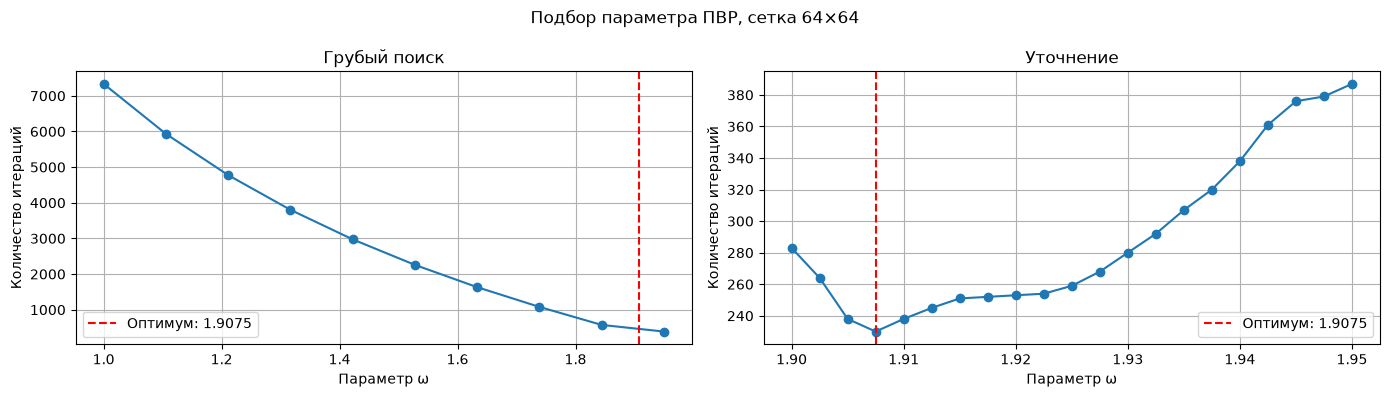

‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒



In [680]:
sor_tuner = SORTuner()
optimal_omega_e = sor_tuner.tune(nx=64, ny=64)


### Выбор параметра релаксации

Скорость сходимости зависит от параметра $\omega$.

Теоретически оптимальный параметр определяется формулой:

$$
\boxed{
\omega_{\mathrm{opt}}=
\frac{2}{1+\sqrt{1-\rho(R_J)^2}},
}
$$

где $R_J$ — матрица перехода метода Якоби.

In [681]:
def theoretical_omega(nx, ny):

    A, _ = SystemAssembler(nx, ny).assemble()

    D_inv = sp.diags(1 / A.diagonal())
    R_J = sp.eye(A.shape[0], format="csr") - D_inv @ A

    rho = abs(sp.linalg.eigs(R_J, k=1, which="LM", return_eigenvectors=False)[0])

    return 2 / (1 + np.sqrt(1 - rho**2))


optimal_omega_t = theoretical_omega(64, 64)


In [682]:
tester = Tester(
    {
        f"ПВР ω({optimal_omega_e})": (SOR.solve, {"omega": optimal_omega_e}),
        f"ПВР ω({optimal_omega_t})": (SOR.solve, {"omega": optimal_omega_t}),
    }
)

tester.test(nx=64, ny=64)



‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒
Сетка: 64×64, размер системы: 3844
Число обусловленности κ₂(A): 2.137e+03
ПВР ω(1.9075): итераций = 230
Невязка = 9.651e-09
Сходимость = да
Оценка погрешности κ₂(A)·η: 2.063e-05
ПВР ω(1.90531701981655): итераций = 234
Невязка = 9.543e-09
Сходимость = да
Оценка погрешности κ₂(A)·η: 2.040e-05
‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒




### 8.3 Этап 3. Реализация и проверка методов сопряжённых градиентов

Реализовать CG без предобуславливания, PCG с диагональным предобуславливателем и PCG с предобуславливателем SSOR. Для SSOR значение $\omega$ выбирается и обосновывается отдельно: параметры ПВР-итерации и предобуславливателя SSOR выполняют разные функции.

Сначала применить все три реализации к тестовой системе этапа 2. Проверить, что пересчитанная непосредственно невязка удовлетворяет заданному порогу, а погрешность решения СЛАУ согласуется с полученной невязкой и обусловленностью матрицы.

Убедиться, что в PCG используются только симметричные положительно определённые предобуславливатели и нигде не формируется $P^{-1}$.

Затем выполнить расчёты назначенного варианта на сетках $N=32,64,128$ при

$$
x^{(0)}=0,\qquad \varepsilon_{\mathrm{res}}=10^{-8}.
$$

Для каждого запуска зарегистрировать:

- Размер системы.
- Число ненулевых элементов.
- Число итераций.
- Число умножений матрицы на вектор.
- Время подготовки предобуславливателя.
- Время итераций.
- Достигнутую истинную невязку.
- Объём памяти CSR-матрицы.

Время измерить не менее трёх раз после одного пробного запуска и использовать медиану.



### Метод сопряжённых градиентов

Метод сопряжённых градиентов (англ. *conjugate gradient*, CG) применим к вещественной симметричной положительно определённой матрице. Он минимизирует квадратичный функционал

$$
\Phi(x) = \frac{1}{2}x^T Ax - b^T x
$$

на последовательности пространств Крылова. В точной арифметике направления $p^{(s)}$ взаимно сопряжены:

$$
(p^{(i)})^T A p^{(j)} = 0, \qquad i \ne j.
$$

Для энергетической нормы

$$
\|\Delta\|_A = (\Delta^T A \Delta)^{1/2}
$$

справедлива оценка

$$
\|\Delta^{(s)}\|_A
\leq
2\left(
\frac{\sqrt{\mu(A)}-1}{\sqrt{\mu(A)}+1}
\right)^s
\|\Delta^{(0)}\|_A.
$$

Каждая итерация требует одного умножения $Ap$, нескольких скалярных произведений и линейного объёма памяти.

Расчётные формулы CG имеют вид:

$$
r^{(0)} = b - Ax^{(0)}, \qquad p^{(0)} = r^{(0)},
$$

$$
\alpha_s =
\frac{(r^{(s)})^T r^{(s)}}
{(p^{(s)})^T Ap^{(s)}},
\qquad
x^{(s+1)} = x^{(s)} + \alpha_s p^{(s)},
$$

$$
r^{(s+1)} = r^{(s)} - \alpha_s Ap^{(s)},
\qquad
\beta_s =
\frac{(r^{(s+1)})^T r^{(s+1)}}
{(r^{(s)})^T r^{(s)}},
$$

$$
p^{(s+1)} = r^{(s+1)} + \beta_s p^{(s)}.
\tag{12}
$$

После каждого обновления проверяется явно вычисленная относительная невязка.


Обычный CG реализован как `ConjugateGradient`: общий алгоритм PCG с тождественным предобуславливателем $P=I$. Его применение даёт $z=r$ и не требует формирования матрицы.


In [683]:
class ConjugateGradient:
    @staticmethod
    def preconditioner(A):
        def apply(r):
            return r.copy()

        return apply

    @staticmethod
    def solve(A, b, x0, eps_res=EPS_RES, maxiter=MAX_ITERS) -> SolveResult:
        return PreconditionedConjugateGradient.solve(
            A,
            b,
            preconditioner=ConjugateGradient.preconditioner(A),
            x0=x0,
            eps_res=eps_res,
            maxiter=maxiter,
        )



### 6.4 Предобусловленный метод сопряжённых градиентов

Предобусловленный метод сопряжённых градиентов (англ. *preconditioned conjugate gradient*, PCG) использует предобуславливатель $P$, который должен приближать $A$, а система $Pz=r$ — решаться существенно дешевле исходной.

Для PCG принципиально, чтобы

$$
P=P^T>0.
$$

Тогда сходимость определяется спектром предобусловленного оператора $P^{-1}A$; в частности, существенны распределение и кластеризация собственных значений.

### Псевдокод PCG

Задать $x^{(0)}$; вычислить:

$$
r^{(0)}=b-Ax^{(0)};
$$

решить

$$
Pz^{(0)}=r^{(0)};
$$

положить

$$
p^{(0)}=z^{(0)}, \qquad \rho_0=(r^{(0)})^Tz^{(0)}.
$$

Для $s=0,1,\ldots$:

1. Вычислить:

   $$
   q^{(s)}=Ap^{(s)}.
   $$

2. Вычислить:

   $$
   \alpha_s=\frac{\rho_s}{(p^{(s)})^Tq^{(s)}}.
   $$

3. Обновить:

   $$
   x^{(s+1)}=x^{(s)}+\alpha_sp^{(s)},
   $$

   $$
   r^{(s+1)}=r^{(s)}-\alpha_sq^{(s)}.
   $$

4. Проверить истинную нормированную невязку:

   $$
   \boxed{
   \eta_{s+1}=
   \frac{\|b-Ax^{(s+1)}\|_2}{\|b\|_2}
   \leq \varepsilon_{\mathrm{res}}.
   }
   $$

   В лабораторной $\varepsilon_{\mathrm{res}}=10^{-8}$.
   Если условие выполнено, завершить итерации.

5. Решить:

   $$
   Pz^{(s+1)}=r^{(s+1)}.
   $$

6. Вычислить:

   $$
   \rho_{s+1}=(r^{(s+1)})^Tz^{(s+1)},
   \qquad
   \beta_s=\frac{\rho_{s+1}}{\rho_s}.
   $$

7. Обновить:

   $$
   p^{(s+1)}=z^{(s+1)}+\beta_sp^{(s)}.
   $$

Из-за накопления погрешностей округления при вычислениях в арифметике конечной точности невязку, обновляемую рекуррентно, следует периодически проверять непосредственным вычислением

$$
b-Ax^{(s)}.
$$

Условие

$$
(p^{(s)})^TAp^{(s)}>0
$$

является также полезной проверкой корректности реализации и положительной определённости матрицы.


In [684]:
class PreconditionedConjugateGradient:
    @staticmethod
    def solve(
        A, b, preconditioner, x0, eps_res=EPS_RES, maxiter=MAX_ITERS
    ) -> SolveResult:
        if not sp.isspmatrix_csr(A):
            raise TypeError("Матрица должна быть в формате CSR")

        b = np.asarray(b, dtype=np.float64)
        x = np.array(x0, dtype=np.float64, copy=True)

        b_norm = np.linalg.norm(b)
        if b_norm == 0:
            raise ValueError("Норма правой части равна нулю")

        matvec_count = 0
        residuals = []
        iterations = 0

        p = None
        rho_previous = None

        while True:
            # Истинная нормированная невязка
            true_r = b - A @ x
            matvec_count += 1
            residuals.append(np.linalg.norm(true_r) / b_norm)

            if residuals[-1] <= eps_res or iterations >= maxiter:
                break

            if iterations == 0:
                r = true_r.copy()

            # Решение Pz = r
            z = preconditioner(r)
            rho = r @ z
            if rho <= 0:
                raise ValueError(
                    "Сбой PCG: rᵀP⁻¹r ≤ 0. Проверьте предобуславливатель "
                    "и численную точность вычислений."
                )

            if p is None:
                p = z.copy()
            else:
                beta = rho / rho_previous
                p = z + beta * p

            q = A @ p
            matvec_count += 1

            denominator = p @ q
            if denominator <= 0:
                raise ValueError("Нарушена положительная определённость матрицы")

            alpha = rho / denominator
            x += alpha * p
            r -= alpha * q

            iterations += 1
            rho_previous = rho

        return SolveResult(
            x=x,
            iterations=iterations,
            residuals=residuals,
            matvec_count=matvec_count,
            converged=residuals[-1] <= eps_res,
        )


**Диагональный предобуславливатель.**

$P=D=\operatorname{diag}(A)$ симметричен и положительно определён. Его применение сводится к покомпонентному делению:

$$
z_i=\frac{r_i}{a_{ii}},\qquad i=1,\ldots,n.
$$

Масштабирование уменьшает влияние различающихся диагональных элементов, но не обязательно обеспечивает быстрое уменьшение невязки.

In [685]:
class DiagonalPCG:
    @staticmethod
    def preconditioner(A):
        diagonal = A.diagonal()

        if np.any(diagonal <= 0):
            raise ValueError("Диагональные элементы должны быть положительными")

        def apply(r):
            return r / diagonal

        return apply

    @staticmethod
    def solve(A, b, x0, eps_res=1e-8, maxiter=50_000) -> SolveResult:
        return PreconditionedConjugateGradient.solve(
            A,
            b,
            preconditioner=DiagonalPCG.preconditioner(A),
            x0=x0,
            eps_res=eps_res,
            maxiter=maxiter,
        )


**SSOR** (англ. *symmetric successive over-relaxation* — симметричная последовательная верхняя релаксация).

При $A=D+L+L^T$ и $0<\omega<2$ определим:

$$
\boxed{
P_{\mathrm{SSOR}}
=
\frac{1}{\omega(2-\omega)}
(D+\omega L)D^{-1}(D+\omega L^T).
}
\tag{13}
$$

Матрица (13) симметрична и положительно определена.

Для применения $P_{\mathrm{SSOR}}^{-1}$ не формируется обратная матрица: выполняются прямая и обратная треугольные подстановки.

Если $B=D+\omega L$, то последовательно решаются:

$$
By=r,
$$

$$
B^Tz_0=Dy,
$$

после чего:

$$
\boxed{z=\omega(2-\omega)z_0.}
$$


In [686]:
class SSORPCG:
    @staticmethod
    def preconditioner(A, omega):
        if not 0 < omega < 2:
            raise ValueError("Параметр ω должен принадлежать интервалу (0, 2)")

        diagonal = A.diagonal()
        if np.any(diagonal <= 0):
            raise ValueError("Диагональные элементы должны быть положительными")

        B = sp.diags(diagonal, format="csr") + omega * sp.tril(A, k=-1, format="csr")
        BT = B.T.tocsr()

        def apply(r):
            y = sp.linalg.spsolve_triangular(B, r, lower=True)
            z = sp.linalg.spsolve_triangular(BT, diagonal * y, lower=False)
            return omega * (2 - omega) * z

        return apply

    @staticmethod
    def solve(A, b, omega, x0, eps_res=1e-8, maxiter=50_000) -> SolveResult:
        return PreconditionedConjugateGradient.solve(
            A,
            b,
            preconditioner=SSORPCG.preconditioner(A, omega),
            x0=x0,
            eps_res=eps_res,
            maxiter=maxiter,
        )


In [687]:
class SSORTuner:
    def __init__(self, eps_res=EPS_RES, maxiter=MAX_ITERS):
        self.eps_res = eps_res
        self.maxiter = maxiter

    @with_separator
    def tune(self, nx, ny):
        A, b = SystemAssembler(nx, ny).assemble()

        def run(omega):
            result = SSORPCG.solve(
                A,
                b,
                omega=omega,
                x0=initial_guess(b),
                eps_res=self.eps_res,
                maxiter=self.maxiter,
            )
            return result.iterations if result.converged else np.inf

        coarse_omegas = np.linspace(0.5, 1.95, 16)
        coarse_iterations = np.array([run(w) for w in coarse_omegas])

        for omega, iterations in zip(coarse_omegas, coarse_iterations):
            print(f"ω = {omega:.4f}, итераций: {iterations}")

        if not np.any(np.isfinite(coarse_iterations)):
            raise RuntimeError("SSOR-PCG не сошёлся ни при одном значении ω")

        best_omega = coarse_omegas[np.argmin(coarse_iterations)]

        # Уточнение около лучшего значения
        fine_omegas = np.linspace(
            max(0.01, best_omega - 0.1),
            min(1.99, best_omega + 0.1),
            21,
        )
        fine_iterations = np.array([run(w) for w in fine_omegas])

        # Выбор лучшего среди всех проверенных значений
        all_omegas = np.concatenate([coarse_omegas, fine_omegas])
        all_iterations = np.concatenate([coarse_iterations, fine_iterations])

        best_index = np.argmin(all_iterations)
        best_omega = float(all_omegas[best_index])

        print(f"\nНаилучший среди проверенных ω = {best_omega:.4f}")
        print(f"Количество итераций: {all_iterations[best_index]:.0f}")

        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        def make_plot(ax, x, y, name):
            ax.plot(x, y, "o-")
            ax.axvline(
                best_omega,
                color="red",
                linestyle="--",
                label=f"Оптимум: {best_omega:.4f}",
            )
            ax.set_xlabel("Параметр ω")
            ax.set_ylabel("Количество итераций")
            ax.set_title(name)
            ax.grid()
            ax.legend()

        make_plot(axes[0], coarse_omegas, coarse_iterations, "Грубый поиск")
        make_plot(axes[1], fine_omegas, fine_iterations, "Уточнение")

        fig.suptitle(f"Подбор параметра SSOR-PCG, сетка {nx}×{ny}")
        plt.tight_layout()
        fig.savefig(FIGURES_DIR / "ssor_tuning.png", dpi=200, bbox_inches="tight")
        plt.show()

        return best_omega



‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒
ω = 0.5000, итераций: 94
ω = 0.5967, итераций: 85
ω = 0.6933, итераций: 77
ω = 0.7900, итераций: 70
ω = 0.8867, итераций: 63
ω = 0.9833, итераций: 58
ω = 1.0800, итераций: 53
ω = 1.1767, итераций: 49
ω = 1.2733, итераций: 45
ω = 1.3700, итераций: 41
ω = 1.4667, итераций: 37
ω = 1.5633, итераций: 34
ω = 1.6600, итераций: 32
ω = 1.7567, итераций: 31
ω = 1.8533, итераций: 31
ω = 1.9500, итераций: 39

Наилучший среди проверенных ω = 1.7067
Количество итераций: 30


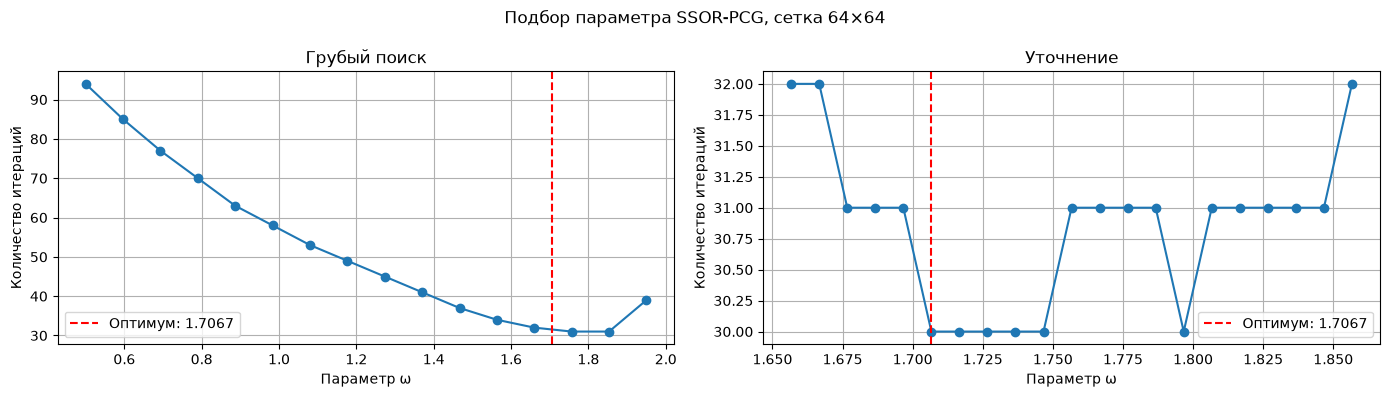

‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒



1.7066666666666666

In [688]:
optimal_omega_ssor = SSORTuner().tune(64, 64)
optimal_omega_ssor


### Бенчмарки решателей

`Benchmark` измеряет полный вызов стационарного решателя. `CGBenchmarker` принимает фабрики предобуславливателей и отдельно измеряет их подготовку и вызов общего PCG. В обоих случаях выполняются один прогрев и не менее трёх измерений; в таблицу попадают медианы. Создание x0 и независимая проверка невязки выполняются вне замеров.

В итоговой таблице «Подготовка, мс» содержит время подготовки предобуславливателя для CG/PCG и `-` для стационарных методов. «Время, мс» для CG/PCG не включает подготовку предобуславливателя. Для обычного CG подготовка — создание тождественного оператора.


In [689]:
import pandas as pd
from time import perf_counter
from statistics import median


class Benchmark:
    def __init__(self, methods, eps_res=EPS_RES, maxiter=MAX_ITERS, repeats=3):
        if repeats < 3:
            raise ValueError("Требуется не менее трёх измерений")

        self.methods = methods
        self.eps_res = eps_res
        self.maxiter = maxiter
        self.repeats = repeats

    def _measure(self, A, b, solve, params, x0):
        start = perf_counter()
        result = solve(
            A, b, x0=x0, eps_res=self.eps_res, maxiter=self.maxiter, **params
        )
        return result, None, perf_counter() - start

    def benchmark(self, nx, ny):

        A, b = SystemAssembler(nx, ny).assemble()
        b_norm = np.linalg.norm(b)
        csr_bytes = A.data.nbytes + A.indices.nbytes + A.indptr.nbytes
        rows = []

        for name, (solve, params) in self.methods.items():
            prep_times = []
            solve_times = []

            for attempt in range(self.repeats + 1):
                x0 = initial_guess(b)
                result, prep_time, solve_time = self._measure(A, b, solve, params, x0)

                eta = np.linalg.norm(b - A @ result.x) / b_norm
                assert np.isfinite(eta)
                assert result.converged == (eta <= self.eps_res)
                assert np.isclose(eta, result.residuals[-1], rtol=1e-5, atol=1e-14)
                assert len(result.residuals) == result.iterations + 1

                if attempt > 0:
                    solve_times.append(solve_time)
                    if prep_time is not None:
                        prep_times.append(prep_time)

            rows.append(
                {
                    "Nx": nx,
                    "Ny": ny,
                    "Метод": name,
                    "Размер системы": A.shape[0],
                    "Ненулевых элементов": A.nnz,
                    "Итераций": result.iterations,
                    "A @ v": result.matvec_count,
                    "Подготовка, мс": median(prep_times) * 1000 if prep_times else "-",
                    "Время, мс": median(solve_times) * 1000,
                    "Истинная невязка": eta,
                    "Сходимость": result.converged,
                    "Память CSR, MB": csr_bytes / (10**6),
                }
            )

        return pd.DataFrame(rows)

    def benchmark_all(self, sizes=((32, 32), (64, 64), (128, 128))):
        return pd.concat(
            [self.benchmark(nx, ny) for nx, ny in sizes],
            ignore_index=True,
        )


class CGBenchmarker(Benchmark):
    def _measure(self, A, b, prepare, params, x0):
        start = perf_counter()
        preconditioner = prepare(A, **params)
        prep_time = perf_counter() - start

        start = perf_counter()
        result = PreconditionedConjugateGradient.solve(
            A,
            b,
            preconditioner=preconditioner,
            x0=x0,
            eps_res=self.eps_res,
            maxiter=self.maxiter,
        )
        solve_time = perf_counter() - start
        assert result.matvec_count == 1 + 2 * result.iterations
        return result, prep_time, solve_time


In [690]:
tester = Tester(
    {
        "CG": (ConjugateGradient.solve, {}),
        "PCG (диагональный)": (DiagonalPCG.solve, {}),
        "PCG (SSOR)": (SSORPCG.solve, {"omega": optimal_omega_ssor}),
    }
)

tester.test_known_solution(u_exact, nx=32, ny=32)

cg_preconditioners = {
    "CG": (ConjugateGradient.preconditioner, {}),
    "PCG (диагональный)": (DiagonalPCG.preconditioner, {}),
    "PCG (SSOR)": (SSORPCG.preconditioner, {"omega": optimal_omega_ssor}),
}
benchmarker = CGBenchmarker(cg_preconditioners)

results = benchmarker.benchmark_all(sizes=((32, 32), (64, 64), (128, 128)))
display(results)



‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒
Число обусловленности κ₂(A): 5.042e+02
Умножений на A: 229
Метод: CG
Число итераций: 114
Нормированная невязка: 8.264e-09
Относительная погрешность: 7.357e-09
Оценка погрешности κ₂(A)·η: 4.167e-06
Критерий остановки достигнут: да
Умножений на A: 207
Метод: PCG (диагональный)
Число итераций: 103
Нормированная невязка: 8.427e-09
Относительная погрешность: 8.019e-09
Оценка погрешности κ₂(A)·η: 4.249e-06
Критерий остановки достигнут: да
Умножений на A: 45
Метод: PCG (SSOR)
Число итераций: 22
Нормированная невязка: 6.435e-09
Относительная погрешность: 2.772e-09
Оценка погрешности κ₂(A)·η: 3.245e-06
Критерий остановки достигнут: да
‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒‒



,Nx,Ny,Метод,Размер системы,Ненулевых элементов,Итераций,A @ v,"Подготовка, мс","Время, мс",Истинная невязка,Сходимость,"Память CSR, MB"
0,32,32,CG,900,4380,67,135,0.000511,1.015422,9.196892e-09,True,0.056164
1,32,32,PCG (диагональный),900,4380,62,125,0.011271,0.946873,8.172721e-09,True,0.056164
2,32,32,PCG (SSOR),900,4380,22,45,0.296932,10.798624,4.875973e-09,True,0.056164
3,64,64,CG,3844,18972,147,295,0.000601,4.893054,8.921271e-09,True,0.243044
4,64,64,PCG (диагональный),3844,18972,130,261,0.019568,4.336820,7.631215e-09,True,0.243044
5,64,64,PCG (SSOR),3844,18972,30,61,0.804413,32.441851,4.073375e-09,True,0.243044
6,128,128,CG,15876,78876,311,623,0.001753,210.905131,9.379151e-09,True,1.010020
7,128,128,PCG (диагональный),15876,78876,266,533,0.104107,133.321294,8.603628e-09,True,1.010020
8,128,128,PCG (SSOR),15876,78876,51,103,1.526970,298.387629,5.549693e-09,True,1.010020


Изменение времени между N=64 и N=128 выглядит подозрительно. Проверим нет ли накладных расходов на распараллеливание sp.linalg.spsolve_triangular

In [691]:
from threadpoolctl import threadpool_limits, threadpool_info

# print(threadpool_info())

with threadpool_limits(limits=1):
    results = benchmarker.benchmark_all()
    display(results)


,Nx,Ny,Метод,Размер системы,Ненулевых элементов,Итераций,A @ v,"Подготовка, мс","Время, мс",Истинная невязка,Сходимость,"Память CSR, MB"
0,32,32,CG,900,4380,67,135,0.000601,3.172096,9.196892e-09,True,0.056164
1,32,32,PCG (диагональный),900,4380,62,125,0.024427,1.683307,8.172721e-09,True,0.056164
2,32,32,PCG (SSOR),900,4380,22,45,0.322130,10.083111,4.875973e-09,True,0.056164
3,64,64,CG,3844,18972,147,295,0.000411,4.776884,8.921271e-09,True,0.243044
4,64,64,PCG (диагональный),3844,18972,130,261,0.018395,4.306844,7.631215e-09,True,0.243044
5,64,64,PCG (SSOR),3844,18972,30,61,0.471082,22.717540,4.073375e-09,True,0.243044
6,128,128,CG,15876,78876,311,623,0.001052,33.456202,9.393540e-09,True,1.010020
7,128,128,PCG (диагональный),15876,78876,266,533,0.065013,30.553586,8.603677e-09,True,1.010020
8,128,128,PCG (SSOR),15876,78876,51,103,0.951882,105.229198,5.549694e-09,True,1.010020


In [692]:
class ReferenceTester:
    def __init__(self, methods, eps_res=EPS_RES, maxiter=MAX_ITERS):
        self.methods = methods
        self.eps_res = eps_res
        self.maxiter = maxiter

    def test(self, nx, ny, methods=None):

        A, b = SystemAssembler(nx, ny).assemble()
        b_norm = np.linalg.norm(b)

        x_ref = sp.linalg.spsolve(A, b)

        assert np.all(np.isfinite(x_ref)), "Контрольное решение содержит NaN или Inf"

        eta_ref = np.linalg.norm(b - A @ x_ref) / b_norm
        assert (
            eta_ref <= self.eps_res
        ), "Контрольное решение не достигло требуемой точности"

        print(f"Сетка: {nx}×{ny}, размер системы: {A.shape[0]}")
        print(f"Невязка контрольного решения: {eta_ref:.3e}")

        norm_ref_2 = np.linalg.norm(x_ref, ord=2)
        norm_ref_inf = np.linalg.norm(x_ref, ord=np.inf)

        rows = []

        selected_methods = (
            self.methods
            if methods is None
            else {name: self.methods[name] for name in methods}
        )

        for name, (solve, params) in selected_methods.items():
            result = solve(
                A,
                b,
                x0=initial_guess(b),
                eps_res=self.eps_res,
                maxiter=self.maxiter,
                **params,
            )

            eta = np.linalg.norm(b - A @ result.x) / b_norm

            delta_2 = np.linalg.norm(result.x - x_ref, ord=2) / norm_ref_2
            delta_inf = np.linalg.norm(result.x - x_ref, ord=np.inf) / norm_ref_inf

            assert (
                result.converged and eta <= self.eps_res
            ), f"Метод {name} не достиг требуемой невязки"

            rows.append(
                {
                    "Nx": nx,
                    "Ny": ny,
                    "Метод": name,
                    "Итераций": result.iterations,
                    "Истинная невязка": eta,
                    "Относительная L2": delta_2,
                    "Относительная L∞": delta_inf,
                }
            )

        return pd.DataFrame(rows)



## 8.4 Этап 4. Независимая проверка решения

Если объём доступной памяти позволяет, получить контрольное решение с помощью прямого решателя для разреженных СЛАУ.

Дополнительно разрешается использовать библиотечную реализацию CG с более строгим порогом невязки.

Для каждого контрольного решения независимо пересчитать невязку и проверить код возврата библиотечной функции.

Сравнить собственное и контрольное решения в относительных нормах $L_2$ и $L_\infty$.

Согласие двух решателей подтверждает корректность решения одной и той же СЛАУ, но не доказывает точность способа получения матрицы из краевой задачи.

Значительное расхождение требует проверки правой части, критерия остановки, порядка нумерации узлов и реализации предобуславливателя.


In [693]:
methods = {
    "Якоби": (Jacobi.solve, {}),
    "Зейдель": (Seidel.solve, {}),
    "ПВР": (SOR.solve, {"omega": optimal_omega_e}),
    "CG": (ConjugateGradient.solve, {}),
    "PCG (диагональный)": (DiagonalPCG.solve, {}),
    "PCG (SSOR)": (SSORPCG.solve, {"omega": optimal_omega_ssor}),
}

tester = ReferenceTester(methods)

with threadpool_limits(limits=1):
    results = pd.concat(
        [
            tester.test(nx=32, ny=32),
            tester.test(nx=64, ny=64),
            tester.test(nx=128, ny=128),
        ],
        ignore_index=True,
    )

display(results)


Сетка: 32×32, размер системы: 900
Невязка контрольного решения: 2.148e-14
Сетка: 64×64, размер системы: 3844
Невязка контрольного решения: 9.842e-14
Сетка: 128×128, размер системы: 15876
Невязка контрольного решения: 3.974e-13


,Nx,Ny,Метод,Итераций,Истинная невязка,Относительная L2,Относительная L∞
0,32,32,Якоби,3547,9.956623e-09,1.301928e-08,1.012615e-08
1,32,32,Зейдель,1775,9.909805e-09,1.288012e-08,1.004659e-08
2,32,32,ПВР,205,9.710940e-09,2.209018e-09,2.297307e-09
3,32,32,CG,67,9.196892e-09,2.167869e-10,2.553220e-10
4,32,32,PCG (диагональный),62,8.172721e-09,1.510782e-10,1.693055e-10
5,32,32,PCG (SSOR),22,4.875973e-09,1.670211e-10,2.202405e-10
6,64,64,Якоби,14667,9.999588e-09,1.307285e-08,1.015984e-08
7,64,64,Зейдель,7335,9.988467e-09,1.303893e-08,1.014049e-08
8,64,64,ПВР,230,9.651315e-09,1.747121e-09,1.880983e-09
9,64,64,CG,147,8.921271e-09,1.189930e-10,1.705137e-10


## 8.5 Этап 5. Оформление результатов вычислительного эксперимента

Сохранить сводную таблицу запусков в формате CSV.

Построить:

1. Графики изменения $\eta_s$ в логарифмическом масштабе для сравниваемых методов.
2. График зависимости числа итераций от $N$.
3. Поле решения на наиболее подробной использованной сетке.

Для выбранного приложения вычислить не менее одной содержательной характеристики: максимум температуры, максимум напряжённости электрического поля, полную массу вещества или интегральный поток через выбранную границу.

Выводы должны быть основаны на численных данных и включать влияние размера матрицы, её обусловленности и предобуславливателя на сходимость.

В выводах следует отдельно отметить случаи стагнации, при которой продолжение итераций не приводит к заметному уменьшению нормы невязки, а также случаи недостижения заданного порога невязки.

In [694]:
from threadpoolctl import threadpool_limits

sizes = ((32, 32), (64, 64), (128, 128))

reference_results = results.copy()

stationary_methods = {
    name: method for name, method in methods.items() if name not in cg_preconditioners
}
benchmarker = Benchmark(stationary_methods)
cg_benchmarker = CGBenchmarker(cg_preconditioners)

with threadpool_limits(limits=1):
    benchmark_results = pd.concat(
        [
            benchmarker.benchmark_all(sizes=sizes),
            cg_benchmarker.benchmark_all(sizes=sizes),
        ],
        ignore_index=True,
    )

summary = reference_results.merge(
    benchmark_results[["Nx", "Ny", "Метод", "A @ v", "Подготовка, мс", "Время, мс"]],
    on=["Nx", "Ny", "Метод"],
    how="left",
    validate="one_to_one",
)

stationary = summary["Метод"].isin(["Якоби", "Зейдель", "ПВР"])
summary.loc[stationary, "A @ v"] = summary.loc[stationary, "Итераций"] + 1

kappas = {}

for nx, ny in sizes:
    A, _ = SystemAssembler(nx, ny).assemble()

    lambda_min = sp.linalg.eigsh(A, k=1, which="SA", return_eigenvectors=False)[0]
    lambda_max = sp.linalg.eigsh(A, k=1, which="LA", return_eigenvectors=False)[0]

    kappas[nx, ny] = lambda_max / lambda_min

    mask = (summary["Nx"] == nx) & (summary["Ny"] == ny)
    summary.loc[mask, "Размер системы"] = A.shape[0]
    summary.loc[mask, "Ненулевых элементов"] = A.nnz
    summary.loc[mask, "Память CSR, MB"] = (
        A.data.nbytes + A.indices.nbytes + A.indptr.nbytes
    ) / 10**6
    summary.loc[mask, "κ₂(A)"] = kappas[nx, ny]

summary["A @ v"] = summary["A @ v"].astype("Int64")

summary.to_csv("results.csv", index=False, encoding="utf-8-sig")

display(summary)
print("Сводная таблица сохранена в results.csv")


,Nx,Ny,Метод,Итераций,Истинная невязка,Относительная L2,Относительная L∞,A @ v,"Подготовка, мс","Время, мс",Размер системы,Ненулевых элементов,"Память CSR, MB",κ₂(A)
0,32,32,Якоби,3547,9.956623e-09,1.301928e-08,1.012615e-08,3548,-,23.391978,900.0,4380.0,0.056164,504.204441
1,32,32,Зейдель,1775,9.909805e-09,1.288012e-08,1.004659e-08,1776,-,25.632350,900.0,4380.0,0.056164,504.204441
2,32,32,ПВР,205,9.710940e-09,2.209018e-09,2.297307e-09,206,-,3.076515,900.0,4380.0,0.056164,504.204441
3,32,32,CG,67,9.196892e-09,2.167869e-10,2.553220e-10,135,0.00049,1.050600,900.0,4380.0,0.056164,504.204441
4,32,32,PCG (диагональный),62,8.172721e-09,1.510782e-10,1.693055e-10,125,0.009438,0.938467,900.0,4380.0,0.056164,504.204441
5,32,32,PCG (SSOR),22,4.875973e-09,1.670211e-10,2.202405e-10,45,0.268138,9.041488,900.0,4380.0,0.056164,504.204441
6,64,64,Якоби,14667,9.999588e-09,1.307285e-08,1.015984e-08,14668,-,218.248686,3844.0,18972.0,0.243044,2137.443705
7,64,64,Зейдель,7335,9.988467e-09,1.303893e-08,1.014049e-08,7336,-,375.374107,3844.0,18972.0,0.243044,2137.443705
8,64,64,ПВР,230,9.651315e-09,1.747121e-09,1.880983e-09,231,-,11.555448,3844.0,18972.0,0.243044,2137.443705
9,64,64,CG,147,8.921271e-09,1.189930e-10,1.705137e-10,295,0.000321,4.657709,3844.0,18972.0,0.243044,2137.443705


Сводная таблица сохранена в results.csv


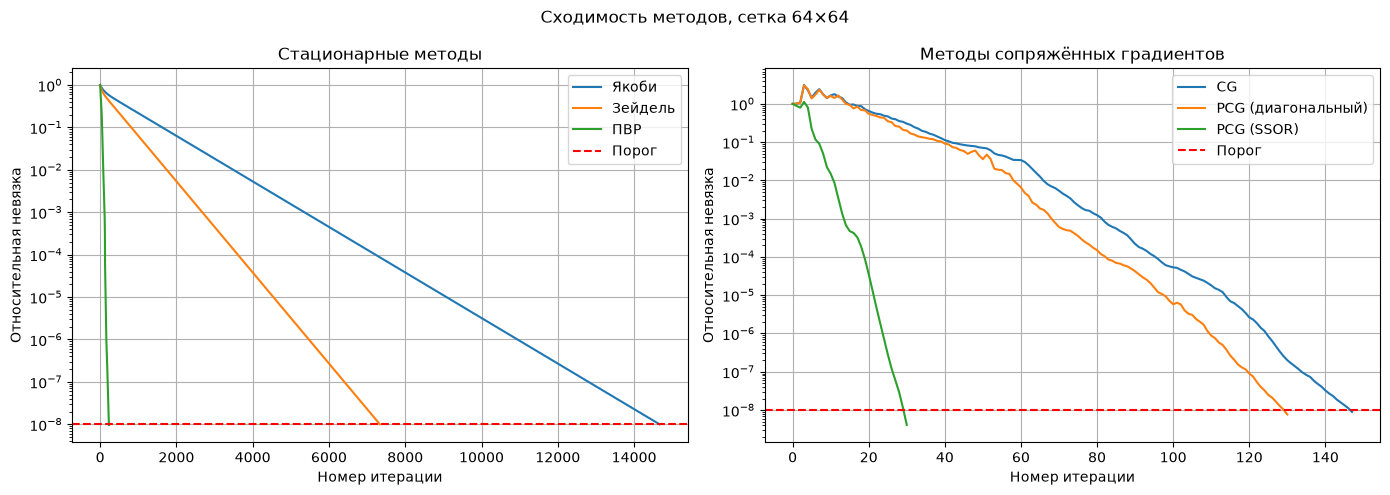

In [695]:
nx = ny = 64
A, b = SystemAssembler(nx, ny).assemble()

histories = {}

with threadpool_limits(limits=1):
    for name, (solve, params) in methods.items():
        result = solve(
            A,
            b,
            x0=initial_guess(b),
            eps_res=EPS_RES,
            maxiter=MAX_ITERS,
            **params,
        )
        histories[name] = result

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

groups = [
    ("Стационарные методы", ["Якоби", "Зейдель", "ПВР"]),
    ("Методы сопряжённых градиентов", ["CG", "PCG (диагональный)", "PCG (SSOR)"]),
]

for ax, (title, names) in zip(axes, groups):
    for name in names:
        residuals = histories[name].residuals
        ax.semilogy(residuals, label=name)

    ax.axhline(EPS_RES, color="red", linestyle="--", label="Порог")
    ax.set_xlabel("Номер итерации")
    ax.set_ylabel("Относительная невязка")
    ax.set_title(title)
    ax.grid()
    ax.legend()

fig.suptitle(f"Сходимость методов, сетка {nx}×{ny}")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "residual_histories.png", dpi=200, bbox_inches="tight")
plt.show()


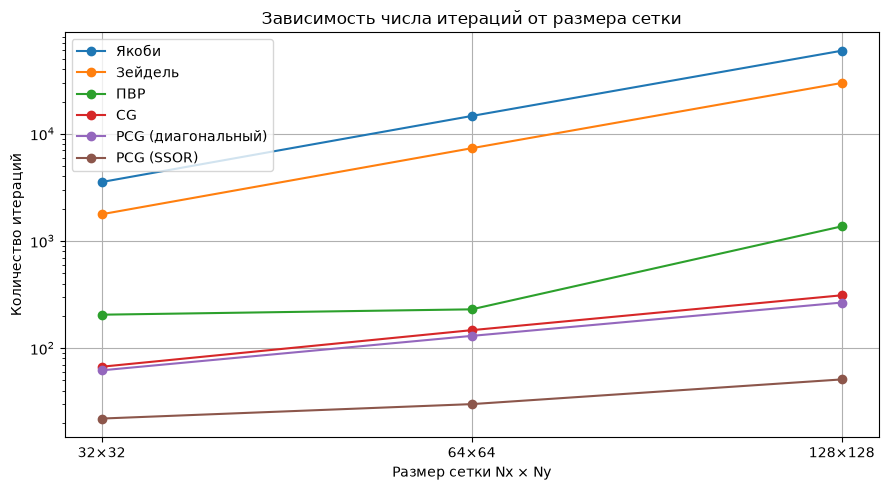

In [696]:
plt.figure(figsize=(9, 5))

for name in methods:
    data = summary[summary["Метод"] == name].sort_values(["Nx", "Ny"])
    labels = [f"{nx}×{ny}" for nx, ny in zip(data["Nx"], data["Ny"])]
    plt.plot(labels, data["Итераций"], "o-", label=name)

plt.yscale("log")
plt.xlabel("Размер сетки Nx × Ny")
plt.ylabel("Количество итераций")
plt.title("Зависимость числа итераций от размера сетки")
plt.grid()
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "iteration_counts.png", dpi=200, bbox_inches="tight")
plt.show()


Максимальная температура: 0.62722526
Координаты максимума: x=0.4961, y=0.5039


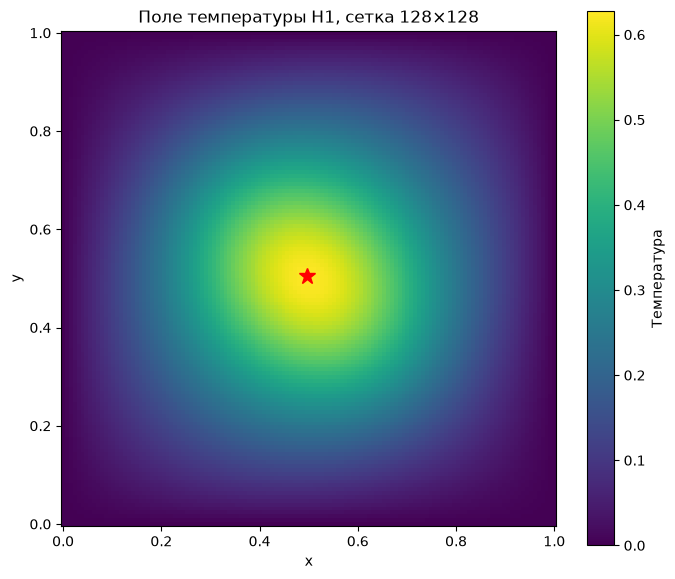

In [702]:
nx = ny = 128
A, b = SystemAssembler(nx, ny).assemble()

with threadpool_limits(limits=1):
    result = DiagonalPCG.solve(
        A,
        b,
        x0=initial_guess(b),
        eps_res=EPS_RES,
        maxiter=MAX_ITERS,
    )

assert result.converged

u_grid = np.zeros((ny, nx))
u_grid[1:-1, 1:-1] = result.x.reshape((ny - 2, nx - 2))

x_grid = np.linspace(0, 1, nx)
y_grid = np.linspace(0, 1, ny)

j_max, i_max = np.unravel_index(np.argmax(u_grid), u_grid.shape)
u_max = u_grid[j_max, i_max]

print(f"Максимальная температура: {u_max:.8f}")
print(f"Координаты максимума: x={x_grid[i_max]:.4f}, y={y_grid[j_max]:.4f}")

fig, ax = plt.subplots(figsize=(7, 6))

image = ax.pcolormesh(x_grid, y_grid, u_grid, shading="auto")
fig.colorbar(image, ax=ax, label="Температура")

ax.plot(x_grid[i_max], y_grid[j_max], "r*", markersize=12)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Поле температуры H1, сетка {nx}×{ny}")
ax.set_aspect("equal")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "temperature_field.png", dpi=200, bbox_inches="tight")
plt.show()
